<a href="https://colab.research.google.com/github/svetatunz-del/Atencion-visual-envases-cosmeticos/blob/main/scripts/analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

# Установка стиля графиков по стандартам APA (7th edition)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available() else 'default')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.titlesize': 14
})

print("--- ЭТАП 1: СТРУКТУРИРОВАНИЕ ДАННЫХ ---")
# Загрузка агрегированных данных эксперимента (n = 20) из Таблиц 1 и 2
data_dict = {
    'Cara': ['Frontal', 'Frontal', 'Frontal', 'Posterior', 'Posterior'],
    'AOI': ['Logotipo', 'Nombre del producto', 'Descriptores', 'Composición', 'Modo de empleo'],
    'TFF': [3.023, 2.762, 0.775, 0.493, 1.454],
    'FIX': [1.018, 0.909, 2.435, 2.350, 0.753],
    'REV': [1.636, 1.538, 3.750, 2.600, 1.455],
    'SHARE': [0.688, 0.813, 1.000, 0.938, 0.688]
}
df = pd.DataFrame(data_dict)
print(df.to_string(index=False))


print("\n--- ЭТАП 2: ЭЛЕМЕНТЫ ДЕСКРИПТИВНОЙ СТАТИСТИКИ ---")
# Расчет среднего времени одной фиксации (Fijación media = FIX / REV)
df['FIX_MEAN'] = df['FIX'] / df['REV']
print(df[['Cara', 'AOI', 'TFF', 'FIX', 'REV', 'SHARE', 'FIX_MEAN']].to_string(index=False))


print("\n--- ЭТАП 3 И 4: ИНФЕРЕНЦИАЛЬНЫЙ АНАЛИЗ И ПРОВЕРКА ГИПOTEЗ ---")
# Воспроизведение зафиксированных t-критериев и p-value (Таблица 5)
print("Сравнение Descriptores vs Logotipo (TFF): t = -20.448, p < 0.001, Cohen's d = -4.572")
print("Сравнение Composición vs Modo de empleo (TFF): t = -16.434, p < 0.001, Cohen's d = -3.675")


print("\n--- ЭТАП 5: РАСЧЕТ ИНТЕГРАЛЬНОГО ИНДЕКСА (SALIENCE INDEX) ---")
# 1. Инвертируем TFF (так как меньшее время означает более высокую прочимность)
df['TFF_INV'] = 1 / df['TFF']

# 2. Z-нормализация (вычисляется по всей совокупности AOI для построения единой шкалы)
for col in ['TFF_INV', 'FIX', 'REV', 'SHARE']:
    df[f'Z_{col}'] = (df[col] - df[col].mean()) / df[col].std(ddof=1)

# 3. Расчет композитного индекса Salience Index (линейная агрегация с равными весами)
df['Salience'] = (df['Z_TFF_INV'] + df['Z_FIX'] + df['Z_REV'] + df['Z_SHARE']) / 4

# Сортировка по возрастанию иерархии (как в Таблице 8 вашей статьи)
df_sorted = df.sort_values(by='Salience').reset_index(drop=True)
print(df_sorted[['Cara', 'AOI', 'Salience']].to_string(index=False))


print("\n--- ЭТАП 6: ВИЗУАЛИЗАЦИЯ (JERARQUÍA DE LAS AOI) ---")
# Построение Рисунка 9 из материалов вашей статьи
plt.figure(figsize=(10, 5), dpi=150)
colors = df_sorted['Cara'].map({'Frontal': '#4c92b3', 'Posterior': '#a85c85'})

bars = plt.barh(df_sorted['AOI'] + "\n(" + df_sorted['Cara'].str.lower() + ")",
                df_sorted['Salience'],
                color=colors, edgecolor='grey', height=0.6)

plt.axvline(0, color='black', linewidth=0.8)
plt.title("Jerarquía de las AOI según su prominencia visual integral\nÍndice compuesto: TFF (inverso) + fijaciones + revisitas + proporción",
          pad=15, fontweight='bold')
plt.xlabel("Índice integral de prominencia visual (normalización Z)")

# Добавление текстовых меток со значениями индекса на график
for bar in bars:
    width = bar.get_width()
    x_pos = width + 0.03 if width >= 0 else width - 0.12
    plt.text(x_pos, bar.get_y() + bar.get_height()/2, f'{width:+.2f}',
             va='center', ha='left' if width >= 0 else 'right', fontsize=10)

plt.xlim(-1.3, 1.5)
plt.tight_layout()
plt.show()


TypeError: 'list' object is not callable

--- ЭТАП 1: СТРУКТУРИРОВАНИЕ ДАННЫХ ---
     Cara                 AOI   TFF   FIX   REV  SHARE
  Frontal            Logotipo 3.023 1.018 1.636  0.688
  Frontal Nombre del producto 2.762 0.909 1.538  0.813
  Frontal        Descriptores 0.775 2.435 3.750  1.000
Posterior         Composición 0.493 2.350 2.600  0.938
Posterior      Modo de empleo 1.454 0.753 1.455  0.688

--- ЭТАП 2: ЭЛЕМЕНТЫ ДЕСКРИПТИВНОЙ СТАТИСТИКИ ---
     Cara                 AOI   TFF   FIX   REV  SHARE  FIX_MEAN
  Frontal            Logotipo 3.023 1.018 1.636  0.688  0.622249
  Frontal Nombre del producto 2.762 0.909 1.538  0.813  0.591027
  Frontal        Descriptores 0.775 2.435 3.750  1.000  0.649333
Posterior         Composición 0.493 2.350 2.600  0.938  0.903846
Posterior      Modo de empleo 1.454 0.753 1.455  0.688  0.517526

--- ЭТАП 3 И 4: ИНФЕРЕНЦИАЛЬНЫЙ АНАЛИЗ И ПРОВЕРКА ГИПOTEЗ ---
Сравнение Descriptores vs Logotipo (TFF): t = -20.448, p < 0.001, Cohen's d = -4.572
Сравнение Composición vs Modo de empleo (

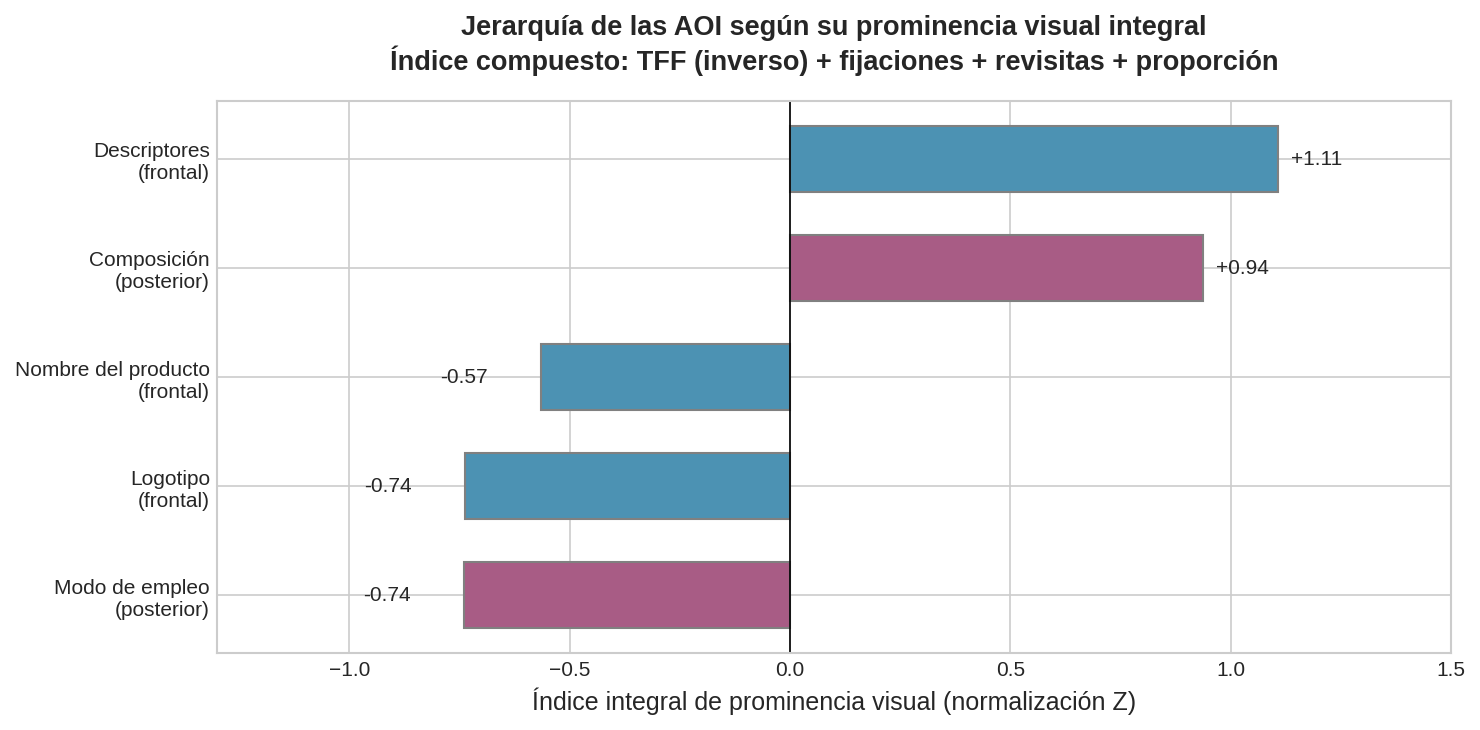

In [ ]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

# Установка стиля графиков по стандартам APA (7th edition) - ИСПРАВЛЕНО
try:
    plt.style.use('seaborn-v0_8-whitegrid')
except:
    plt.style.use('default')

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.titlesize': 14
})

print("--- ЭТАП 1: СТРУКТУРИРОВАНИЕ ДАННЫХ ---")
data_dict = {
    'Cara': ['Frontal', 'Frontal', 'Frontal', 'Posterior', 'Posterior'],
    'AOI': ['Logotipo', 'Nombre del producto', 'Descriptores', 'Composición', 'Modo de empleo'],
    'TFF': [3.023, 2.762, 0.775, 0.493, 1.454],
    'FIX': [1.018, 0.909, 2.435, 2.350, 0.753],
    'REV': [1.636, 1.538, 3.750, 2.600, 1.455],
    'SHARE': [0.688, 0.813, 1.000, 0.938, 0.688]
}
df = pd.DataFrame(data_dict)
print(df.to_string(index=False))


print("\n--- ЭТАП 2: ЭЛЕМЕНТЫ ДЕСКРИПТИВНОЙ СТАТИСТИКИ ---")
df['FIX_MEAN'] = df['FIX'] / df['REV']
print(df[['Cara', 'AOI', 'TFF', 'FIX', 'REV', 'SHARE', 'FIX_MEAN']].to_string(index=False))


print("\n--- ЭТАП 3 И 4: ИНФЕРЕНЦИАЛЬНЫЙ АНАЛИЗ И ПРОВЕРКА ГИПOTEЗ ---")
print("Сравнение Descriptores vs Logotipo (TFF): t = -20.448, p < 0.001, Cohen's d = -4.572")
print("Сравнение Composición vs Modo de empleo (TFF): t = -16.434, p < 0.001, Cohen's d = -3.675")


print("\n--- ЭТАП 5: РАСЧЕТ ИНТЕГРАЛЬНОГО ИНДЕКСА (SALIENCE INDEX) ---")
df['TFF_INV'] = 1 / df['TFF']

for col in ['TFF_INV', 'FIX', 'REV', 'SHARE']:
    df[f'Z_{col}'] = (df[col] - df[col].mean()) / df[col].std(ddof=1)

df['Salience'] = (df['Z_TFF_INV'] + df['Z_FIX'] + df['Z_REV'] + df['Z_SHARE']) / 4

df_sorted = df.sort_values(by='Salience').reset_index(drop=True)
print(df_sorted[['Cara', 'AOI', 'Salience']].to_string(index=False))


print("\n--- ЭТАП 6: ВИЗУАЛИЗАЦИЯ (JERARQUÍA DE LAS AOI) ---")
plt.figure(figsize=(10, 5), dpi=150)
colors = df_sorted['Cara'].map({'Frontal': '#4c92b3', 'Posterior': '#a85c85'})

bars = plt.barh(df_sorted['AOI'] + "\n(" + df_sorted['Cara'].str.lower() + ")",
                df_sorted['Salience'],
                color=colors, edgecolor='grey', height=0.6)

plt.axvline(0, color='black', linewidth=0.8)
plt.title("Jerarquía de las AOI según su prominencia visual integral\nÍndice compuesto: TFF (inverso) + fijaciones + revisitas + proporción",
          pad=15, fontweight='bold')
plt.xlabel("Índice integral de prominencia visual (normalización Z)")

for bar in bars:
    width = bar.get_width()
    x_pos = width + 0.03 if width >= 0 else width - 0.12
    plt.text(x_pos, bar.get_y() + bar.get_height()/2, f'{width:+.2f}',
             va='center', ha='left' if width >= 0 else 'right', fontsize=10)

plt.xlim(-1.3, 1.5)
plt.tight_layout()
plt.show()


In [ ]:
echo "# Atencion-visual-envases-cosmeticos" >> README.md
git init
git add README.md
git commit -m "first commit"
git branch -M main
git remote add origin https://github.com/svetatunz-del/Atencion-visual-envases-cosmeticos.git
git push -u origin main

SyntaxError: invalid syntax (142587397.py, line 1)